# XGBoost explainability

Explains the tuned XGBoost model from `xgboost.ipynb` in two ways, both set up like the LSTM/GCN Integrated Gradients notebooks (all-zeros baseline, predicted-class logit, the same balanced test samples):

- **Part 1: baseline SHAP.** Exact Shapley values computed against a single all-zeros reference input (`TreeExplainer` in interventional mode).
- **Part 2: TreeIG.** Exact Integrated Gradients for tree ensembles, the same method the LSTM and GCN use.

Grouped permutation importance is a model-agnostic cross-check. As in the LSTM and GCN notebooks, importance is reported per **base feature** (the 59 features, timesteps collapsed) and per **timestep** (t0-t4), globally and for each class.

In [1]:
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import shap
import joblib

from sklearn.preprocessing import label_binarize
from sklearn.metrics import average_precision_score

In [2]:
RANDOM_STATE = 42
DATA_DIR = "../../data/processed"
MODEL_DIR = "../../models"
MODEL_NAME = "xgboost_augmented"
CLASSES = ['Backdoor', 'CommInj', 'DoS', 'Reconn', 'normal']
ATTACK_CLASSES = CLASSES[:-1]

# fixed colour per class so every plot uses the same mapping
CLASS_COLORS = dict(zip(CLASSES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))

cols = json.load(open(f"{DATA_DIR}/feature_cols.json"))
COLS = cols["numeric"] + cols["categorical"]
N_STEPS = 5

def to_tabular(X):
    return pd.DataFrame(
        X.reshape(X.shape[0], -1),
        columns=[f"t{t}_{c}" for t in range(X.shape[1]) for c in COLS],
    )

X_test = to_tabular(np.load(f"{DATA_DIR}/X_test.npy"))
y_test = np.argmax(np.load(f"{DATA_DIR}/y_test.npy"), axis=1)

model = joblib.load(f"{MODEL_DIR}/{MODEL_NAME}.joblib")
y_pred = model.predict(X_test)

# Part 1: Baseline SHAP

## Explain set

The same samples as the LSTM/GCN IG notebooks: `balanced_idx(y_test, per_class=200, seed=42)`, i.e. up to 200 random test windows per class (fewer if a class has fewer). Part 2 (TreeIG) reuses this set, so both methods explain exactly the same windows.

In [3]:
def balanced_idx(y, per_class=200, seed=42):
    rng = np.random.default_rng(seed)
    idx = [rng.choice(np.where(y == c)[0], min(per_class, (y == c).sum()), replace=False)
           for c in np.unique(y)]
    return np.concatenate(idx)

explain_idx = balanced_idx(y_test, per_class=200, seed=42)
X_explain = X_test.iloc[explain_idx]
y_explain = y_test[explain_idx]
pred_explain = y_pred[explain_idx]

print(f'{len(explain_idx)} samples')
print(pd.Series(y_explain).map(dict(enumerate(CLASSES))).value_counts())

412 samples
normal      200
DoS          91
CommInj      51
Backdoor     39
Reconn       31
Name: count, dtype: int64


## Baseline SHAP values

Standard `TreeExplainer(model)` compares each feature against the training distribution, so its reference point is the average prediction. Here the reference is a **single all-zeros input** (the training mean after standard scaling), the same baseline the LSTM/GCN IG uses. With one reference row, interventional TreeSHAP computes the exact *baseline Shapley value*: each feature's average contribution when it is switched from 0 to its actual value, over every order of switching the features.

Like IG, the attributions for a class add up to `f(x) - f(0)` for that class's logit. The check below compares against `f(0)` from the model itself: SHAP's reported base value is off by up to ~5e-4 because it reads XGBoost 3's per-class intercept slightly wrong, but the attributions are unaffected.

In [4]:
zero_baseline = np.zeros((1, X_test.shape[1]))
explainer = shap.TreeExplainer(model, data=zero_baseline, feature_perturbation='interventional', model_output='raw')
expl = explainer(X_explain)

# values: (n_samples, n_features, n_classes), in log-odds (margin) space
print(expl.values.shape)

margin_0 = model.predict(pd.DataFrame(zero_baseline, columns=X_test.columns), output_margin=True)[0]
margin_x = model.predict(X_explain, output_margin=True)
print('max completeness error, all classes:', np.abs(expl.values.sum(axis=1) - (margin_x - margin_0)).max())

# the target, as for IG: the logit of the predicted class
shap_pred = expl.values[np.arange(len(X_explain)), :, pred_explain]

(412, 295, 5)
max completeness error, all classes: 2.085696905851364e-06


## Aggregating to base features and timesteps

Same aggregation as the LSTM/GCN notebooks (and Part 2): |SHAP| of the predicted-class logit, summed over t0-t4 (per base feature) or over features (per timestep), then averaged over samples.

- **Global:** mean over all samples.
- **Per class:** mean over the **correctly predicted** samples of each class.

`share` is relative to all 59 features. Compare shares and ranks, not raw values.

In [5]:
shap_abs = np.abs(shap_pred).reshape(len(X_explain), N_STEPS, len(COLS))
correct = pred_explain == y_explain

def importance_table(scores):
    df = pd.DataFrame({'feature': COLS, 'importance': scores})
    df = df.sort_values('importance', ascending=False).reset_index(drop=True)
    df['share'] = df['importance'] / df['importance'].sum()
    df['rank'] = np.arange(1, len(df) + 1)
    return df

shap_feat_df = importance_table(shap_abs.sum(axis=1).mean(axis=0))

shap_time_df = pd.DataFrame({'timestep': [f't{t}' for t in range(N_STEPS)],
                             'time_importance': shap_abs.sum(axis=2).mean(axis=0)})
shap_time_df['share'] = shap_time_df['time_importance'] / shap_time_df['time_importance'].sum()

shap_per_class = {}
for c, name in enumerate(CLASSES):
    mask = correct & (y_explain == c)
    if mask.sum():
        shap_per_class[name] = importance_table(shap_abs[mask].sum(axis=1).mean(axis=0))

# wide table used by the later sections: per-class importance plus the global score
feat_imp = pd.DataFrame({name: df.set_index('feature')['importance'] for name, df in shap_per_class.items()})
feat_imp['overall'] = shap_feat_df.set_index('feature')['importance']
feat_imp = feat_imp.sort_values('overall', ascending=False)

display(shap_feat_df.head(20))
display(shap_time_df)

,feature,importance,share,rank
0,src_rate,0.657508,0.080900,1
1,duration_sum,0.589757,0.072564,2
2,run_time_sum,0.567378,0.069811,3
3,tot_load,0.500718,0.061609,4
4,mean,0.416925,0.051299,5
5,idle_mean,0.400767,0.049311,6
6,tot_rate,0.329405,0.040530,7
7,tot_pkts,0.314750,0.038727,8
8,src_int_pkt_mean,0.300069,0.036921,9
9,dst_load,0.267679,0.032935,10


,timestep,time_importance,share
0,t0,1.543590,0.189925
1,t1,1.593941,0.196120
2,t2,1.681069,0.206840
3,t3,1.578030,0.194162
4,t4,1.730753,0.212953


## 1. Global feature and timestep importance

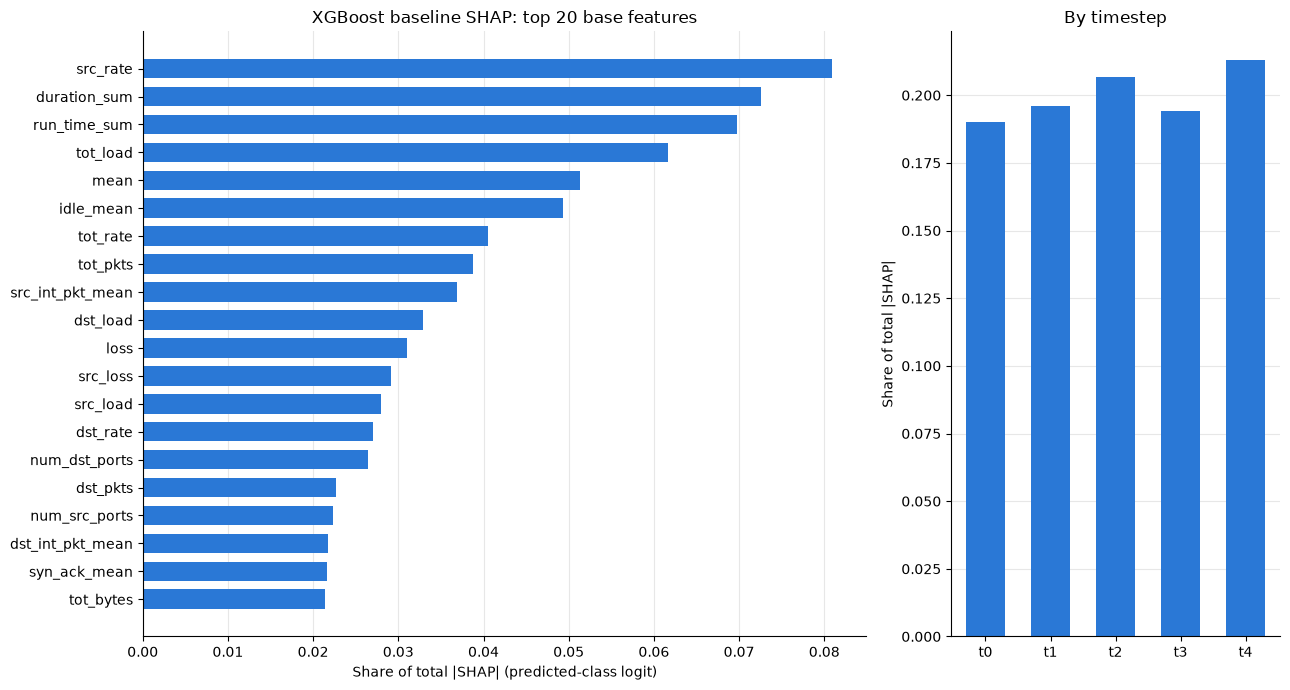

In [6]:
TOP_N = 20
top = shap_feat_df.head(TOP_N)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]
ax.barh(top.feature, top.share, color=CLASS_COLORS['Backdoor'], height=0.7)
ax.set_xlabel('Share of total |SHAP| (predicted-class logit)')
ax.set_title(f'XGBoost baseline SHAP: top {TOP_N} base features')

ax = axes[1]
ax.bar(shap_time_df.timestep, shap_time_df.share, color=CLASS_COLORS['Backdoor'], width=0.6)
ax.set_ylabel('Share of total |SHAP|')
ax.set_title('By timestep')

for ax in axes:
    ax.grid(axis='x' if ax is axes[0] else 'y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Top 10 features for each class

Mean |SHAP| of the predicted-class logit over the **correctly predicted** samples of each class, summed over t0-t4.

In [7]:
for name, df in shap_per_class.items():
    n = (correct & (y_explain == CLASSES.index(name))).sum()
    print(f'\n{name}: {n} samples')
    display(df.head(10))


Backdoor: 38 samples


,feature,importance,share,rank
0,idle_mean,2.641971,0.276484,1
1,src_loss,1.816624,0.190111,2
2,src_load,0.644265,0.067423,3
3,src_rate,0.629056,0.065831,4
4,dst_ttl_mean,0.532885,0.055767,5
5,num_src_ports,0.526309,0.055079,6
6,src_pkts,0.492747,0.051566,7
7,tot_pkts,0.347285,0.036344,8
8,src_app_bytes,0.245780,0.025721,9
9,tot_load,0.190374,0.019923,10



CommInj: 51 samples


,feature,importance,share,rank
0,tot_load,1.345414,0.167876,1
1,idle_mean,0.788416,0.098376,2
2,src_load,0.696185,0.086867,3
3,tcp_rtt_mean,0.608245,0.075895,4
4,syn_ack_mean,0.423214,0.052807,5
5,tot_rate,0.372877,0.046526,6
6,src_rate,0.337317,0.042089,7
7,duration_sum,0.326241,0.040707,8
8,src_int_pkt_mean,0.284976,0.035558,9
9,dst_load,0.280270,0.034971,10



DoS: 91 samples


,feature,importance,share,rank
0,run_time_sum,2.377828,0.244135,1
1,duration_sum,2.302219,0.236372,2
2,mean,1.884218,0.193455,3
3,src_port_registered,0.610573,0.062688,4
4,dst_load,0.536914,0.055126,5
5,src_int_pkt_mean,0.460152,0.047244,6
6,num_src_ports,0.407382,0.041826,7
7,src_pkts,0.332598,0.034148,8
8,dst_pkts,0.269941,0.027715,9
9,src_ttl_mean,0.269495,0.027669,10



Reconn: 29 samples


,feature,importance,share,rank
0,num_dst_ports,2.922355,0.341120,1
1,dport_dynamic,1.222128,0.142656,2
2,dport_registered,0.856950,0.100030,3
3,tot_app_bytes,0.664092,0.077518,4
4,src_app_bytes,0.490616,0.057268,5
5,dst_rate,0.360804,0.042116,6
6,duration_mean,0.280996,0.032800,7
7,src_ttl_mean,0.277592,0.032403,8
8,src_int_pkt_mean,0.267934,0.031275,9
9,src_jitter_mean,0.247707,0.028914,10



normal: 199 samples


,feature,importance,share,rank
0,src_rate,1.141366,0.160408,1
1,tot_load,0.641520,0.090160,2
2,tot_pkts,0.574989,0.080809,3
3,tot_rate,0.573293,0.080571,4
4,loss,0.502585,0.070634,5
5,tot_bytes,0.339843,0.047762,6
6,dst_rate,0.325848,0.045795,7
7,src_int_pkt_mean,0.275448,0.038712,8
8,dst_int_pkt_mean,0.263431,0.037023,9
9,dst_bytes,0.227031,0.031907,10


In [8]:
# one table to read across classes: rank 1-10 as rows, one column per class
pd.DataFrame(
    {name: df.feature.head(10).values for name, df in shap_per_class.items()},
    index=pd.RangeIndex(1, 11, name='rank'),
)

,Backdoor,CommInj,DoS,Reconn,normal
rank,,,,,
1,idle_mean,tot_load,run_time_sum,num_dst_ports,src_rate
2,src_loss,idle_mean,duration_sum,dport_dynamic,tot_load
3,src_load,src_load,mean,dport_registered,tot_pkts
4,src_rate,tcp_rtt_mean,src_port_registered,tot_app_bytes,tot_rate
5,dst_ttl_mean,syn_ack_mean,dst_load,src_app_bytes,loss
6,num_src_ports,tot_rate,src_int_pkt_mean,dst_rate,tot_bytes
7,src_pkts,src_rate,num_src_ports,duration_mean,dst_rate
8,tot_pkts,duration_sum,src_pkts,src_ttl_mean,src_int_pkt_mean
9,src_app_bytes,src_int_pkt_mean,dst_pkts,src_int_pkt_mean,dst_int_pkt_mean


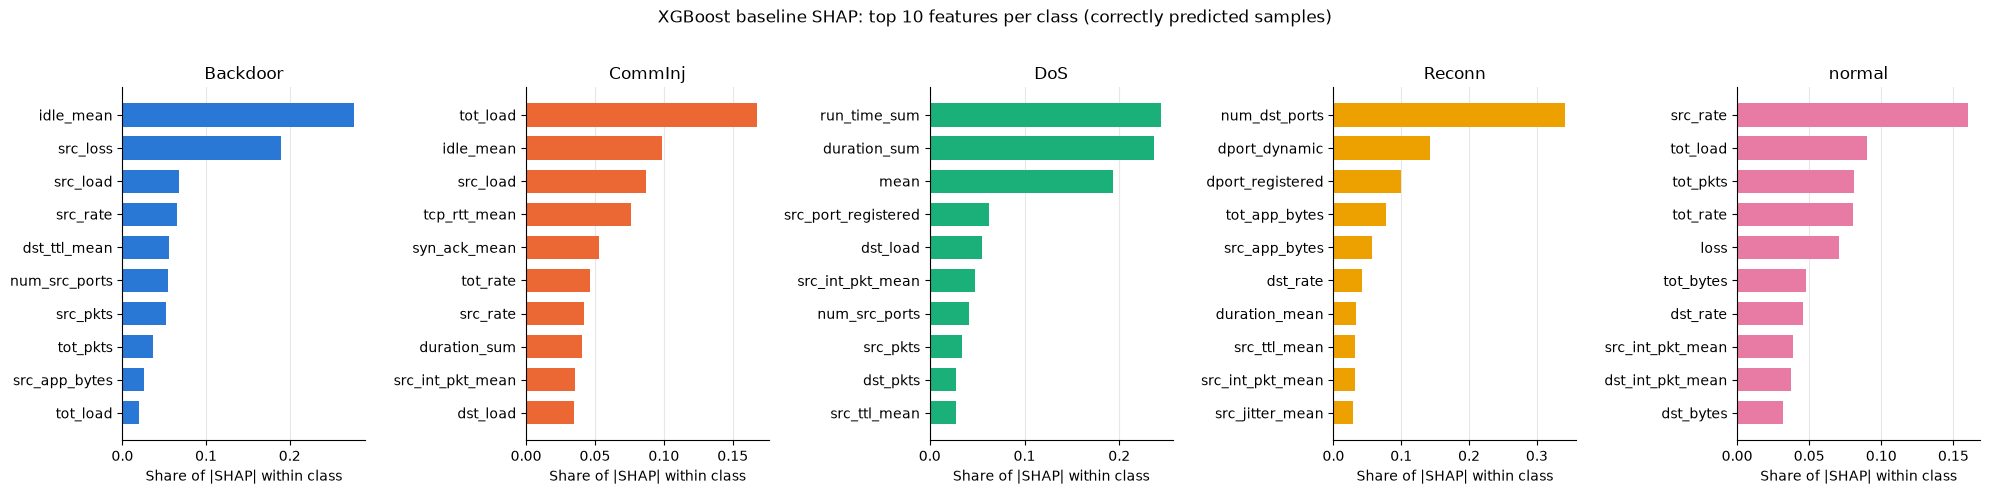

In [9]:
fig, axes = plt.subplots(1, len(shap_per_class), figsize=(20, 4.8))
for ax, (name, df) in zip(axes, shap_per_class.items()):
    top10_c = df.head(10)[::-1]
    ax.barh(top10_c.feature, top10_c.share, color=CLASS_COLORS[name], height=0.7)
    ax.set_title(name)
    ax.set_xlabel('Share of |SHAP| within class')
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('XGBoost baseline SHAP: top 10 features per class (correctly predicted samples)', y=1.02)
plt.tight_layout()
plt.show()

## 3. Timestep importance by class

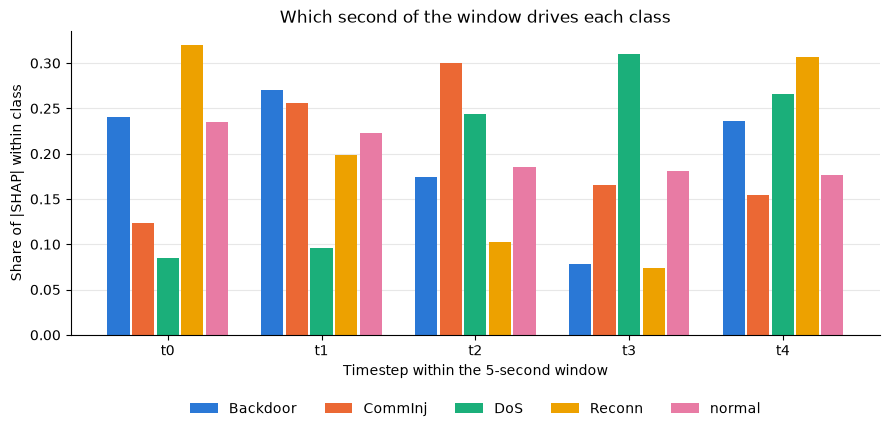

,Backdoor,CommInj,DoS,Reconn,normal
t0,0.241,0.124,0.085,0.319,0.235
t1,0.270,0.255,0.096,0.198,0.223
t2,0.175,0.300,0.243,0.102,0.185
t3,0.078,0.166,0.310,0.073,0.181
t4,0.236,0.154,0.266,0.306,0.176


In [10]:
time_share = pd.DataFrame({
    name: shap_abs[correct & (y_explain == CLASSES.index(name))].sum(axis=2).mean(axis=0)
    for name in shap_per_class
}, index=[f't{t}' for t in range(N_STEPS)])
time_share = time_share / time_share.sum(axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.16
x = np.arange(N_STEPS)
for i, cls in enumerate(time_share.columns):
    ax.bar(x + (i - 2) * width, time_share[cls], width=width * 0.9,
           color=CLASS_COLORS[cls], label=cls)

ax.set_xticks(x, time_share.index)
ax.set_xlabel('Timestep within the 5-second window')
ax.set_ylabel('Share of |SHAP| within class')
ax.set_title('Which second of the window drives each class')
ax.legend(ncols=5, loc='upper center', bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

time_share.round(3)

## 4. Beeswarm per attack class

Each dot is one window in the explain set. Position is the baseline SHAP value for that class's logit (relative to the all-zeros input); colour is the (scaled) feature value. Shows the **direction** of each effect, not just its size.

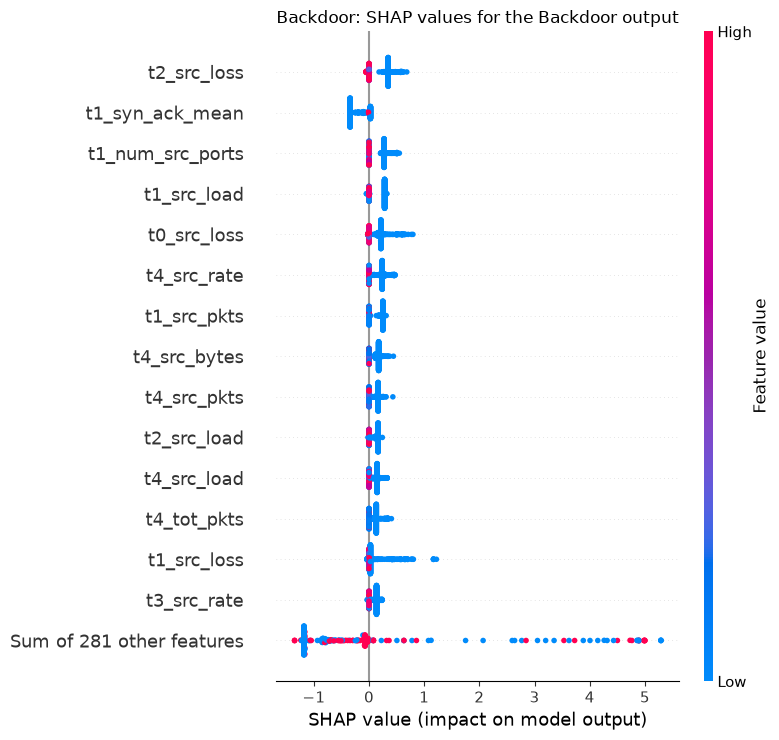

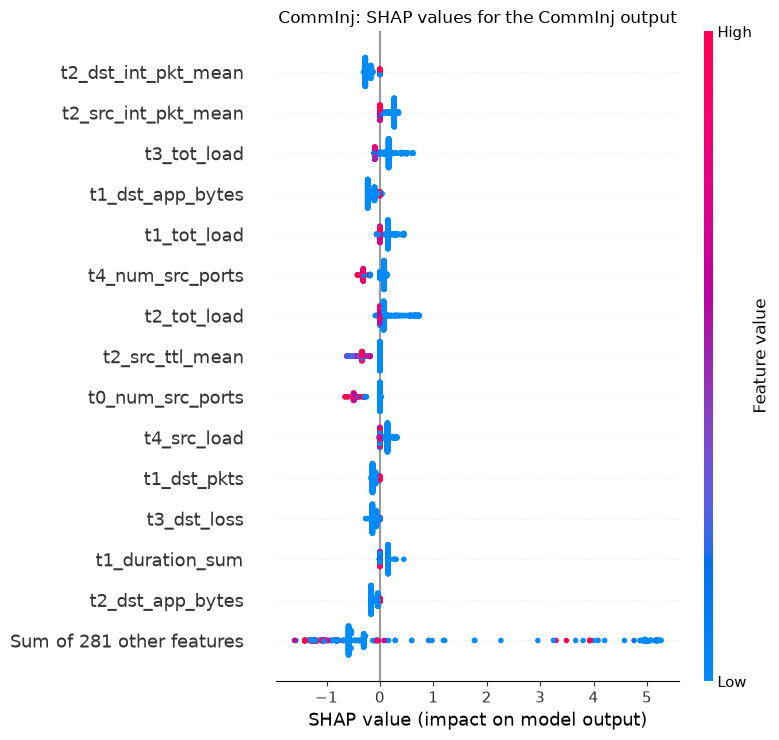

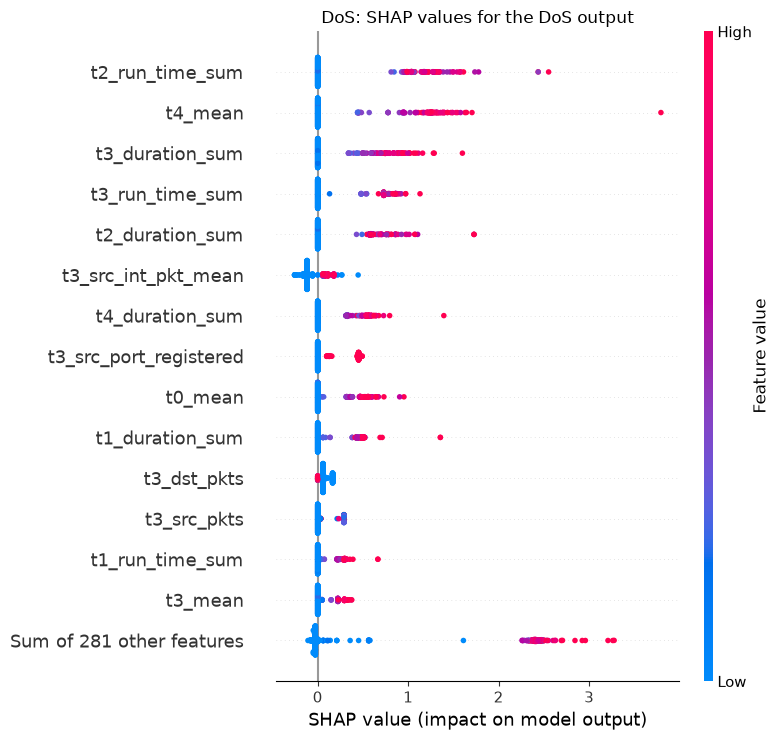

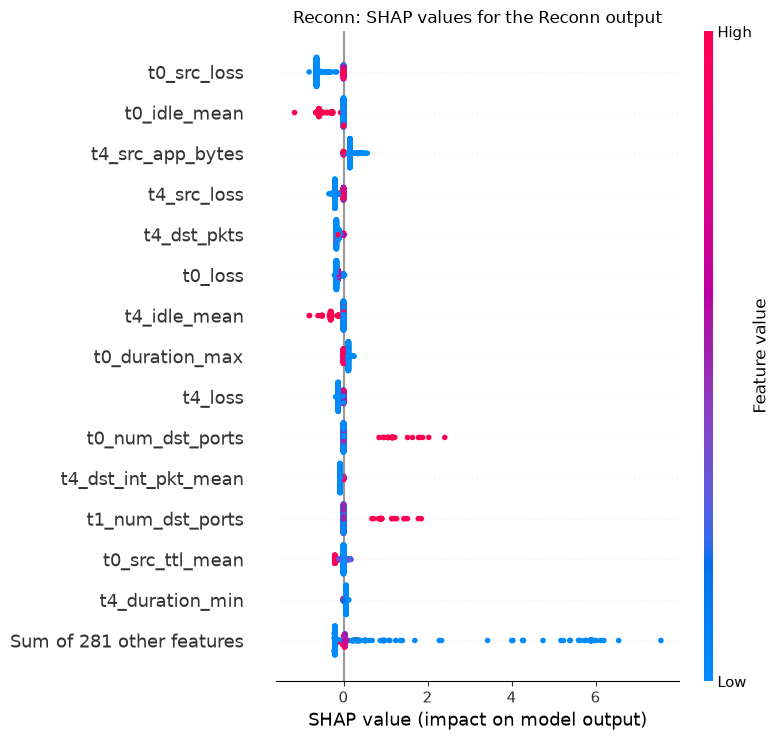

In [11]:
for cls in ATTACK_CLASSES:
    c = CLASSES.index(cls)
    shap.plots.beeswarm(expl[:, :, c], max_display=15, show=False)
    plt.title(f'{cls}: SHAP values for the {cls} output')
    plt.tight_layout()
    plt.show()

## 5. Dependence plots for the top 3 base features

A dependence plot needs a single column, so each base feature uses its highest-ranked timestep column, on the class output where that feature matters most.

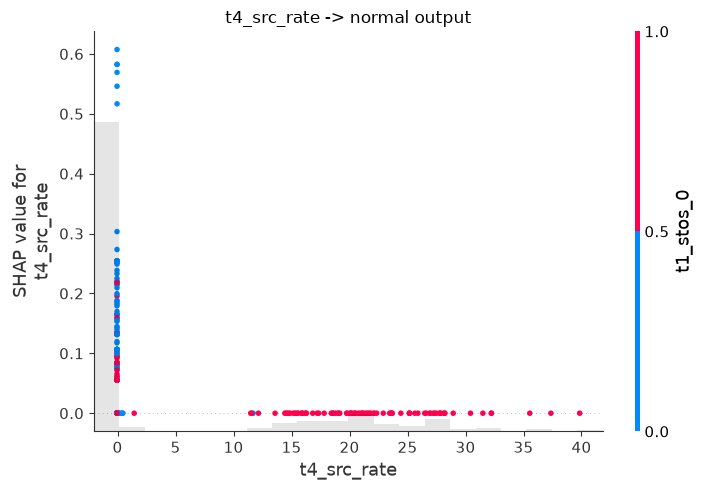

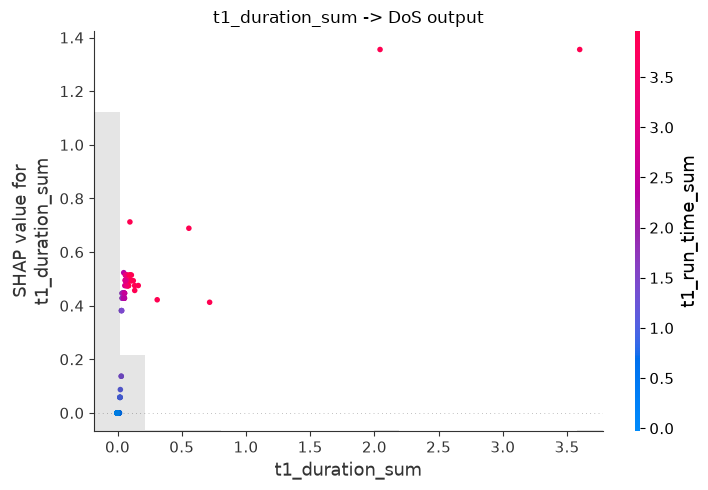

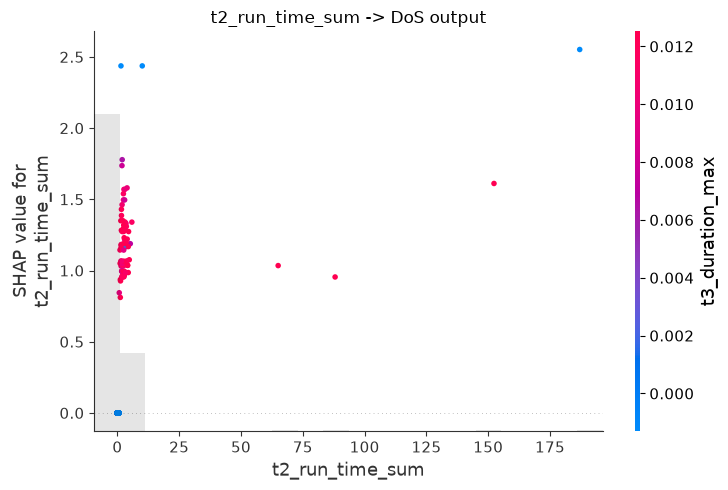

In [12]:
import warnings

col_imp = pd.Series(np.abs(expl.values).mean(axis=(0, 2)), index=X_explain.columns)

for feature in feat_imp.index[:3]:
    column = col_imp[[f"t{t}_{feature}" for t in range(N_STEPS)]].idxmax()
    cls = feat_imp.loc[feature, CLASSES].idxmax()
    c = CLASSES.index(cls)
    # colour picks the strongest interacting column; constant columns trigger a
    # harmless divide-by-zero warning inside its correlation step
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        shap.plots.scatter(expl[:, column, c], color=expl[:, :, c], show=False)
    plt.title(f'{column} -> {cls} output')
    plt.tight_layout()
    plt.show()

## 6. Local explanations (waterfalls)

One correctly classified window per attack class, then up to 5 misclassified test windows. SHAP for the misclassified windows is computed separately because normal-traffic false positives may not be in the sampled explain set.

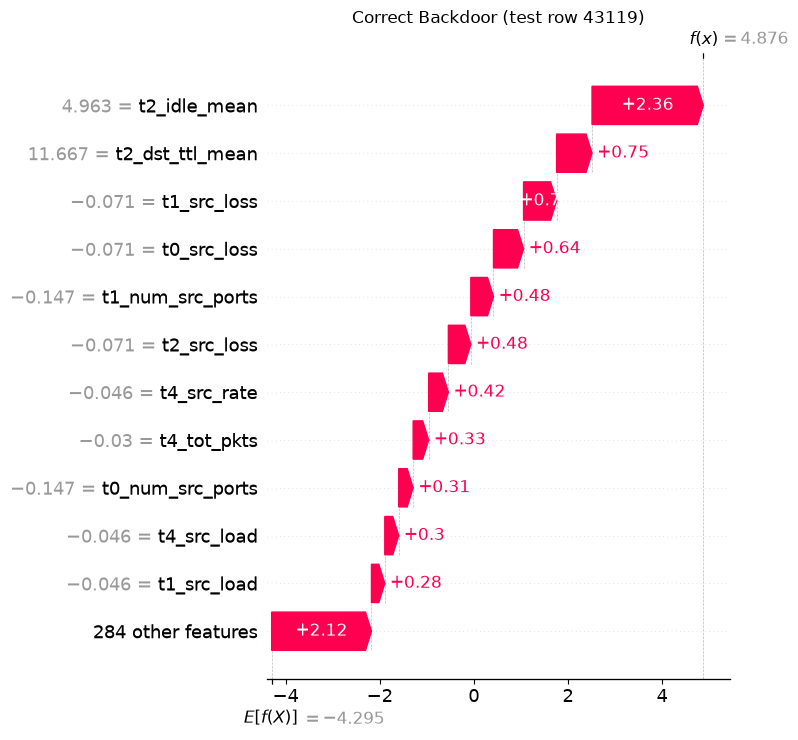

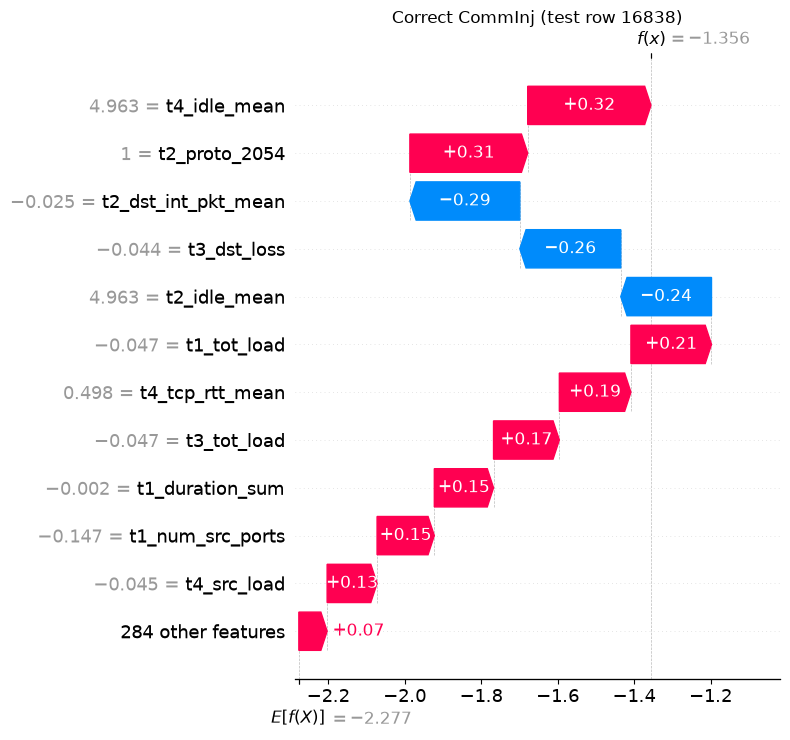

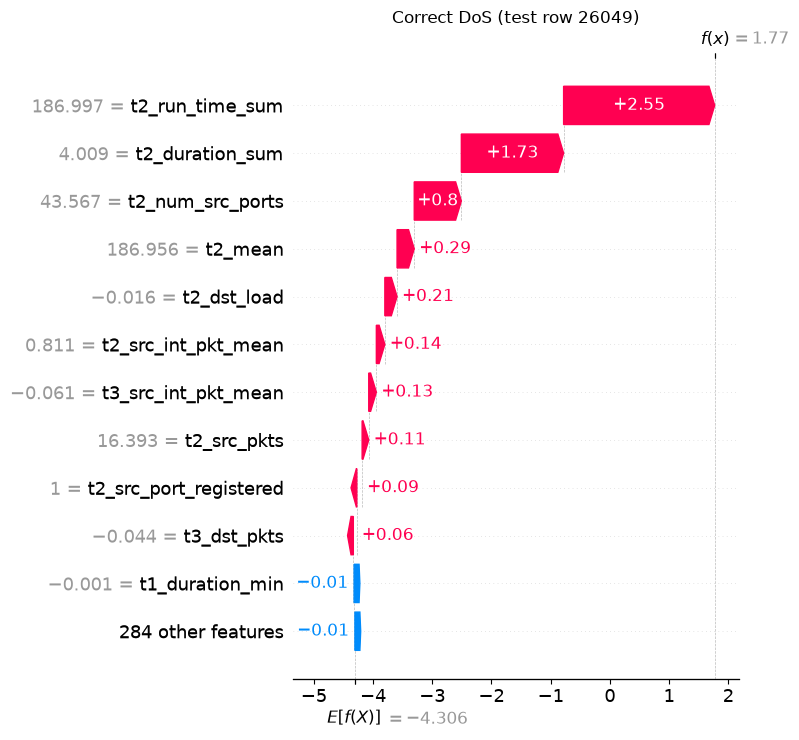

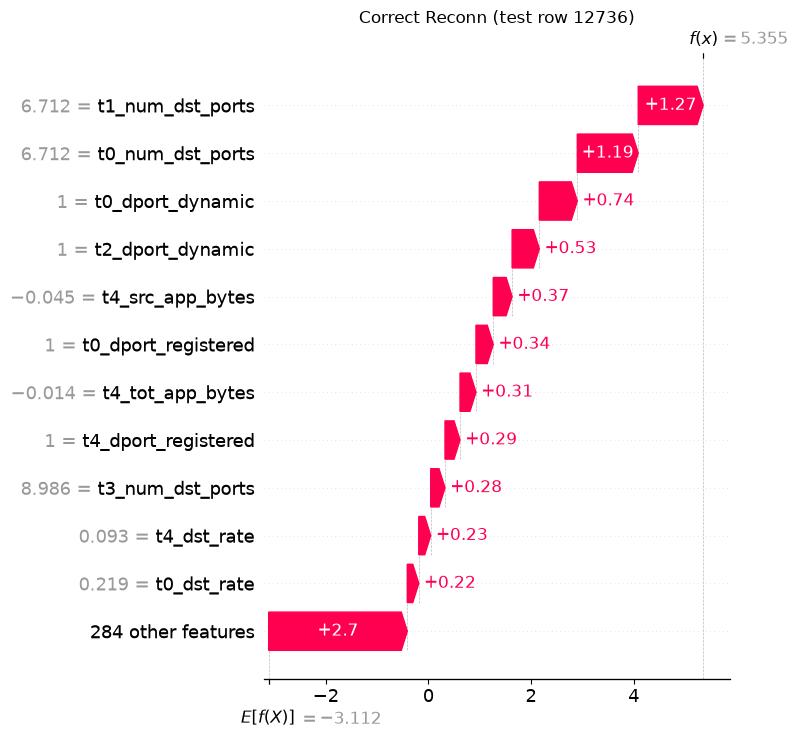

In [13]:
for cls in ATTACK_CLASSES:
    c = CLASSES.index(cls)
    hits = np.where((y_explain == c) & (y_pred[explain_idx] == c))[0]
    if len(hits) == 0:
        print(f'no correctly classified {cls} window')
        continue
    i = hits[0]
    shap.plots.waterfall(expl[i, :, c], max_display=12, show=False)
    plt.title(f'Correct {cls} (test row {explain_idx[i]})')
    plt.tight_layout()
    plt.show()

27 misclassified test windows, showing 5


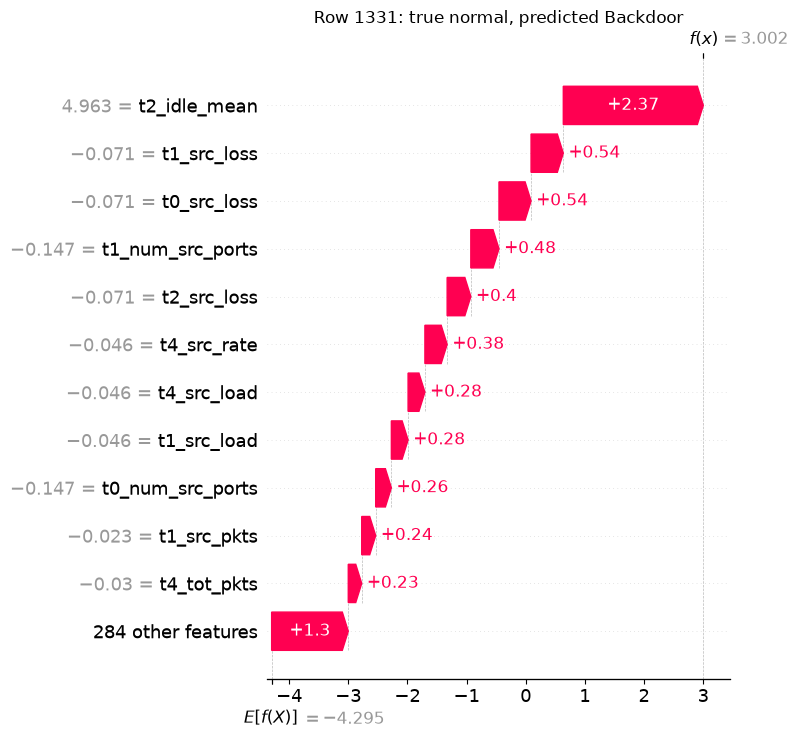

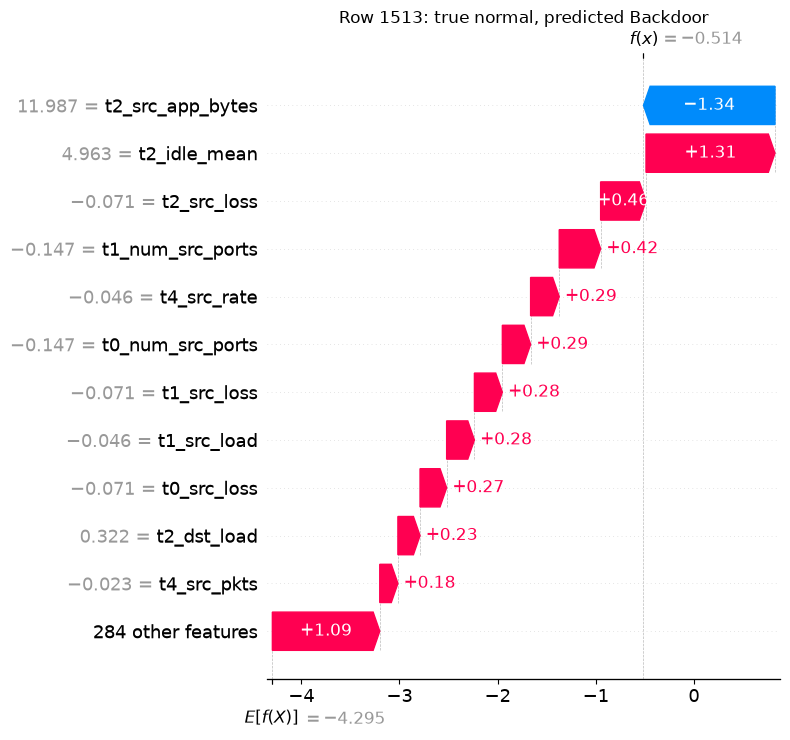

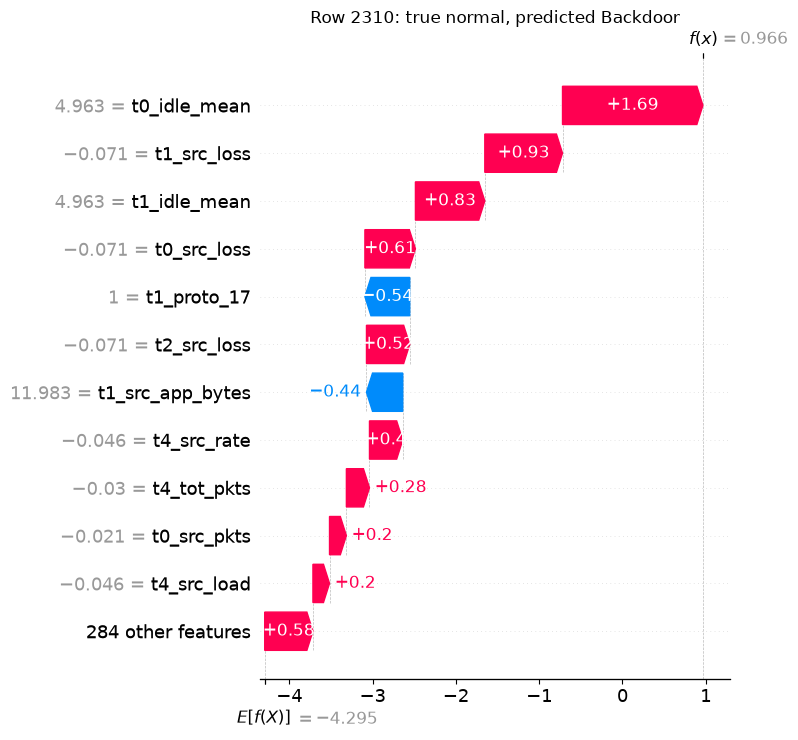

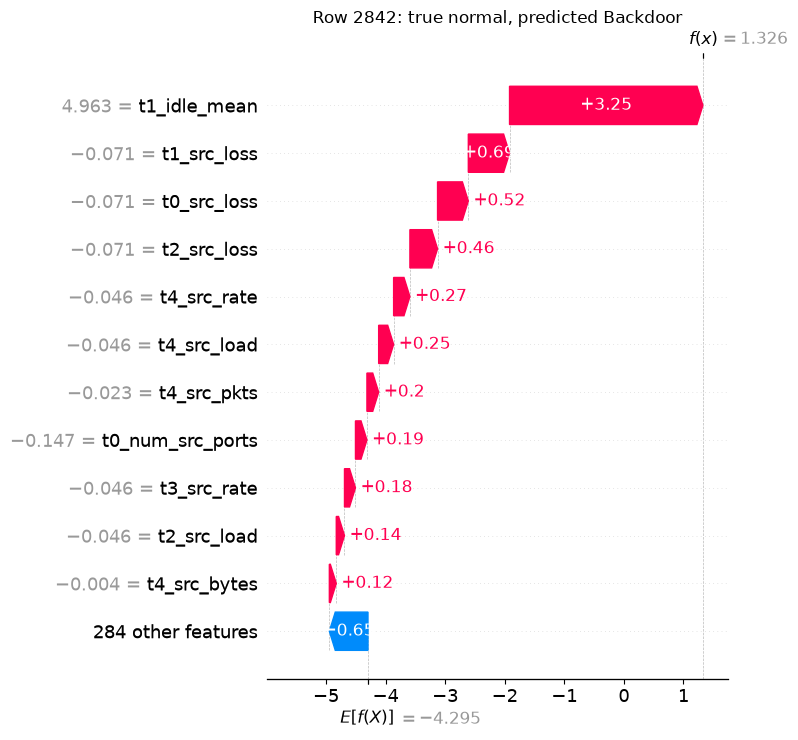

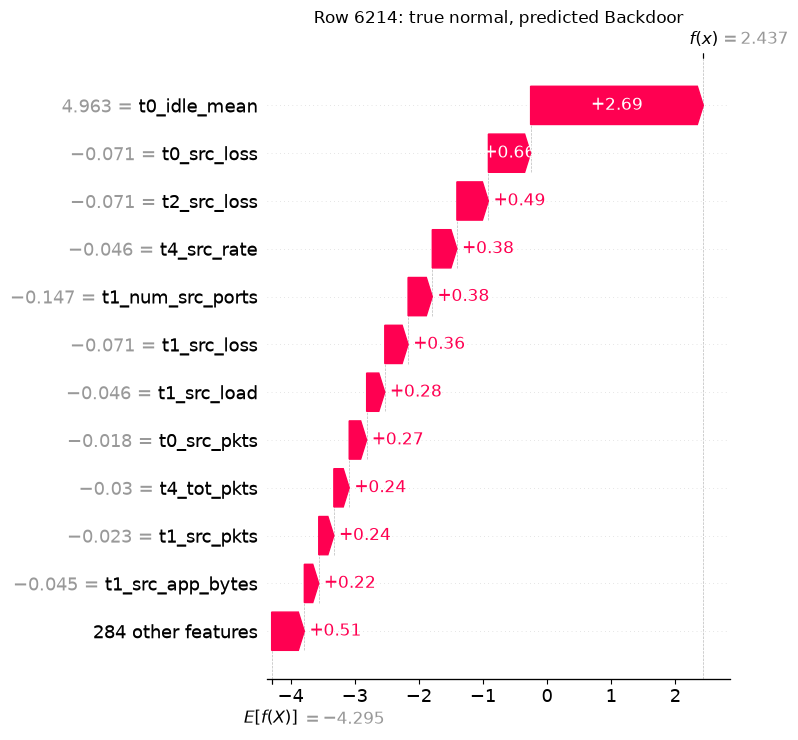

In [14]:
wrong_idx = np.where(y_pred != y_test)[0][:5]
print(f'{(y_pred != y_test).sum()} misclassified test windows, showing {len(wrong_idx)}')

if len(wrong_idx):
    expl_wrong = explainer(X_test.iloc[wrong_idx])
    for j, row in enumerate(wrong_idx):
        true_cls, pred_cls = CLASSES[y_test[row]], CLASSES[y_pred[row]]
        # explain the class the model chose, i.e. why it got this one wrong
        shap.plots.waterfall(expl_wrong[j, :, y_pred[row]], max_display=12, show=False)
        plt.title(f'Row {row}: true {true_cls}, predicted {pred_cls}')
        plt.tight_layout()
        plt.show()

## 7. Grouped permutation importance (cross-check)

Shuffles all 5 timestep columns of a base feature together (same permutation, so each window stays internally consistent) and measures the drop in macro PR-AUC on the full test set. This does not rely on the model's internals, so agreement with the SHAP ranking is a sanity check.

In [15]:
def multiclass_average_precision(y_true, y_proba):
    y_true_binary = label_binarize(y_true, classes=np.arange(len(CLASSES)))
    return average_precision_score(y_true_binary, y_proba, average='macro')

N_REPEATS = 5
base_score = multiclass_average_precision(y_test, model.predict_proba(X_test))
print(f'baseline macro PR-AUC: {base_score:.4f}')

perm_rng = np.random.default_rng(RANDOM_STATE)
drops = {}
X_perm = X_test.copy()
for feature in COLS:
    group = [f"t{t}_{feature}" for t in range(N_STEPS)]
    original = X_test[group].values
    scores = []
    for _ in range(N_REPEATS):
        X_perm[group] = original[perm_rng.permutation(len(X_test))]
        scores.append(base_score - multiclass_average_precision(y_test, model.predict_proba(X_perm)))
    X_perm[group] = original
    drops[feature] = scores

perm_imp = pd.DataFrame({
    'mean_drop': {f: np.mean(s) for f, s in drops.items()},
    'std_drop': {f: np.std(s) for f, s in drops.items()},
}).sort_values('mean_drop', ascending=False)

perm_imp.head(20)

baseline macro PR-AUC: 0.9828


,mean_drop,std_drop
idle_mean,0.157943,0.004919
src_app_bytes,0.008337,0.001699
tot_pkts,0.006021,0.000353
dst_int_pkt_mean,0.005103,0.000254
proto_17,0.003573,0.000102
tcp_rtt_mean,0.002199,0.000498
dst_load,0.001800,0.000248
tot_load,0.001743,0.000484
src_pkts,0.001399,0.000180
src_jitter_mean,0.001337,0.000149


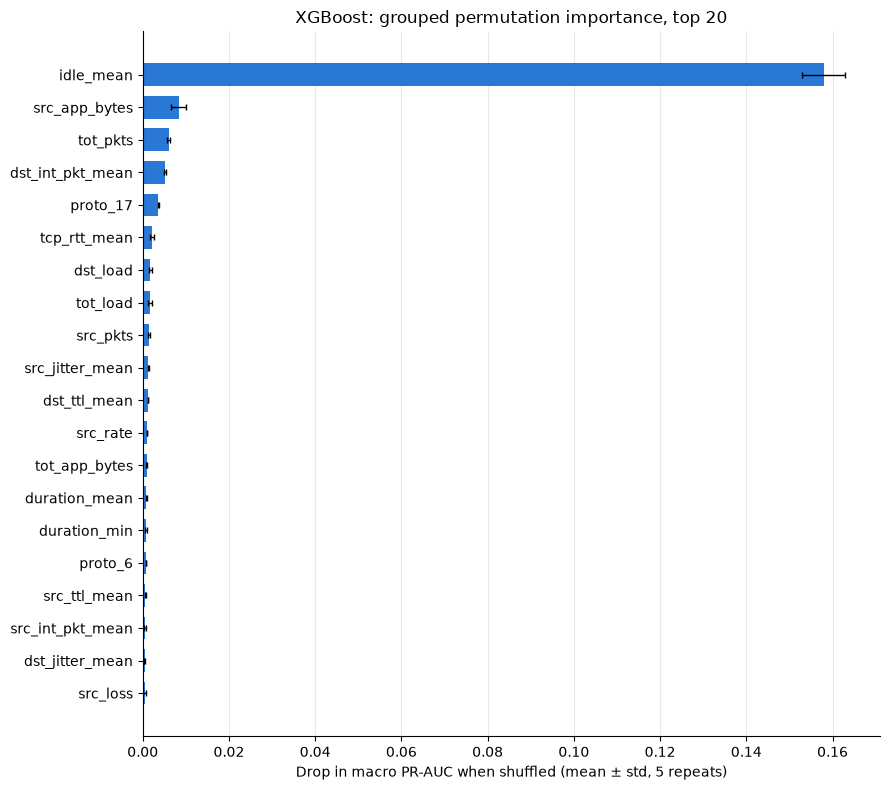

Spearman rank correlation, SHAP vs permutation (all 59 features): 0.185
Top 10 shared: ['dst_load', 'idle_mean', 'tot_load', 'tot_pkts']


In [16]:
top_perm = perm_imp.head(TOP_N)[::-1]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top_perm.index, top_perm['mean_drop'], xerr=top_perm['std_drop'],
        color=CLASS_COLORS['Backdoor'], height=0.7, error_kw={'elinewidth': 1, 'capsize': 2})
ax.set_xlabel(f'Drop in macro PR-AUC when shuffled (mean ± std, {N_REPEATS} repeats)')
ax.set_title(f'XGBoost: grouped permutation importance, top {TOP_N}')
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

shap_rank = feat_imp['overall'].rank(ascending=False)
perm_rank = perm_imp['mean_drop'].rank(ascending=False)
rank_corr = pd.concat([shap_rank, perm_rank], axis=1).corr(method='spearman').iloc[0, 1]
print(f'Spearman rank correlation, SHAP vs permutation (all {len(COLS)} features): {rank_corr:.3f}')
print('Top 10 shared:', sorted(set(feat_imp.index[:10]) & set(perm_imp.index[:10])))

## 8. IP-pair shortcut check

Attacks in this dataset come from only 7 source-destination IP pairs, and those pairs never carry normal traffic. Features that mostly identify the host (TTL, DSCP) rather than the attack's behaviour can therefore act as a label proxy, which would not generalise to new attacker machines.

In [17]:
HOST_FEATURES = ['src_ttl_mean', 'dst_ttl_mean', 'src_dsb_mean']

pd.DataFrame({
    'shap_rank': shap_rank[HOST_FEATURES].astype(int),
    'perm_rank': perm_rank[HOST_FEATURES].astype(int),
    'share_of_total_shap': (feat_imp.loc[HOST_FEATURES, 'overall'] / feat_imp['overall'].sum()).round(3),
})

,shap_rank,perm_rank,share_of_total_shap
src_ttl_mean,28,17,0.012
dst_ttl_mean,36,11,0.006
src_dsb_mean,52,38,0.000


### `idle_mean` is a timestamp leak

`idle_mean` ranks near the top of both SHAP and permutation importance. In the raw CSV, `IdleTime` is not an idle duration but a **Unix timestamp** (~1.5488e9, i.e. 30 Jan 2019), and each attack type was recorded in its own time block. So after scaling, the value of a non-empty second encodes *when* it was captured, and the trees split on differences in the 4th decimal place to tell attack types apart.

In [18]:
trees = model.get_booster().trees_to_dataframe()
idle_splits = trees[trees.Feature.str.contains('idle_mean', na=False)]
print(f"splits on idle_mean: {len(idle_splits)} of {(trees.Feature != 'Leaf').sum()}")
print(idle_splits.Split.round(4).value_counts())

# value range of idle_mean in non-empty seconds (empty seconds are zero-filled before scaling)
idle_cols = [f"t{t}_idle_mean" for t in range(N_STEPS)]
for c, cls in enumerate(CLASSES):
    v = X_test.loc[y_test == c, idle_cols].values.ravel()
    v = v[v > 1]
    print(f"{cls:9s} {v.min():.4f} - {v.max():.4f}")

splits on idle_mean: 712 of 3631
Split
4.9632    361
4.9631    237
4.9628    114
Name: count, dtype: int64
Backdoor  4.9631 - 4.9632
CommInj   4.9631 - 4.9631
DoS       4.9628 - 4.9628
Reconn    4.9628 - 4.9628
normal    4.9628 - 4.9632


**Implication:** part of the reported performance comes from recording time, not traffic behaviour. Since every model here uses the same 59 features, the LSTM, CNN and GCN results are likely affected too. Dropping `idle_mean` in preprocessing (or converting it to a real duration, if that was intended) and retraining would give an honest number.

## 9. Export

In [19]:
out = feat_imp.rename(columns={c: f'shap_{c}' for c in CLASSES + ['overall']})
out['shap_share'] = shap_feat_df.set_index('feature')['share']
out['shap_rank'] = shap_feat_df.set_index('feature')['rank']
out = out.join(perm_imp)
out.index.name = 'feature'
out.to_csv(f'{MODEL_DIR}/xgboost_feature_importance.csv')
out.head()

,shap_Backdoor,shap_CommInj,shap_DoS,shap_Reconn,shap_normal,shap_overall,shap_share,shap_rank,mean_drop,std_drop
feature,,,,,,,,,,
src_rate,0.629056,0.337317,0.000000,0.001104,1.141366,0.657508,0.080900,1,0.000996,0.000088
duration_sum,0.087431,0.326241,2.302219,0.005626,0.065868,0.589757,0.072564,2,0.000008,0.000488
run_time_sum,0.082307,0.197695,2.377828,0.003090,0.020155,0.567378,0.069811,3,-0.000073,0.000082
tot_load,0.190374,1.345414,0.000040,0.012698,0.641520,0.500718,0.061609,4,0.001743,0.000484
mean,0.004285,0.001467,1.884218,0.000000,0.000360,0.416925,0.051299,5,-0.000044,0.000059


# Part 2: Integrated Gradients (TreeIG)

The LSTM (`lstm_explain.ipynb`) and GCN (`gcn.ipynb`) are explained with captum Integrated Gradients. Plain IG cannot run on XGBoost because a tree ensemble is piecewise constant, so its gradient is zero almost everywhere. [TreeIG](https://pypi.org/project/treeig/) computes IG **exactly** for tree ensembles: along the straight path from the baseline to the input, the prediction only changes where the path crosses a split threshold, and each jump is credited to the feature that crossed.

To make the three models comparable, this section copies the LSTM/GCN IG setup:

| Setting | Value |
|---|---|
| Baseline | all-zeros input (= training mean after standard scaling) |
| Target | margin (logit) of the **predicted** class |
| Samples | `balanced_idx(y_test, per_class=200, seed=42)`, same function as `lstm_explain.ipynb`; the same windows as Part 1 |
| Aggregation | \|attr\| summed over t0-t4 (per feature) or over features (per timestep), then mean over samples |
| Per class | mean over **correctly predicted** samples of each class |

Compare **shares and ranks only**: each model's logits are on its own scale, so raw magnitudes are not comparable.

In [20]:
from treeig import TreeIG
from scipy.stats import spearmanr

# same balanced samples as Part 1 (balanced_idx defined there)
ig_idx = explain_idx
X_ig = X_explain
y_ig = y_explain
pred_ig = pred_explain

print(f'{len(ig_idx)} samples')

412 samples


### Ties between simultaneous split crossings

Sometimes several features cross a split at exactly the same point on the path, for example timestep copies of a feature with equal values. TreeIG only implements `tie_policy="first"`, which processes a tie in a fixed order instead of sharing it fairly. To reduce this, attributions are averaged over 64 baselines jittered by ~1e-6 around zero, which breaks interior ties in random order. The jitter does not change the baseline prediction (checked below).

Ties that sit exactly at the **end** of the path cannot be broken this way. They come from values that equal a split threshold, e.g. one-hot features, which XGBoost splits at 1.0. Jittering the input instead would push values across thresholds and change predictions, so these remaining ties are left to TreeIG's fixed order, and their share is reported below.

In [21]:
N_JITTER = 64
jitter_baselines = np.random.default_rng(RANDOM_STATE).normal(0.0, 1e-6, size=(N_JITTER, X_test.shape[1]))
zero_baseline_1d = np.zeros(X_test.shape[1])

def treeig_attributions(X, pred, baseline):
    # TreeIG takes one class target per explainer, so group rows by predicted class
    attr = np.zeros(X.shape)
    for c in np.unique(pred):
        rows = pred == c
        explainer_c = TreeIG(model, target=int(c))
        attr[rows] = explainer_c.attribute(X.values[rows].astype(np.float64), baseline=baseline)
    return attr

ig_attr = treeig_attributions(X_ig, pred_ig, jitter_baselines)
ig_attr_first = treeig_attributions(X_ig, pred_ig, zero_baseline_1d)

margin_jitter = model.predict(pd.DataFrame(jitter_baselines, columns=X_test.columns), output_margin=True)
print('max |f(jittered baseline) - f(0)|:', np.abs(margin_jitter - margin_0).max())

def tied_share(baseline):
    # share of |jump| mass on crossings shared by more than one feature
    tied, total = 0.0, 0.0
    for c in np.unique(pred_ig):
        rows = np.where(pred_ig == c)[0]
        tr = TreeIG(model, target=int(c)).trace(X_ig.values[rows].astype(np.float64), baseline=baseline)
        for r in range(len(rows)):
            n = tr['counts'][r]
            ev = pd.DataFrame({'t': np.round(tr['times'][r, :n], 12), 'f': tr['features'][r, :n],
                               'j': np.abs(tr['jumps'][r, :n])})
            n_feats = ev.groupby('t').f.nunique()
            tied += ev.loc[ev.t.isin(n_feats[n_feats > 1].index), 'j'].sum()
            total += ev.j.sum()
    return tied / total

print(f'share of |jump| mass at tied crossings, zero baseline:     {tied_share(zero_baseline_1d):.3f}')
print(f'share of |jump| mass at tied crossings, jittered baseline: {tied_share(jitter_baselines[0]):.3f}')

max |f(jittered baseline) - f(0)|: 0.0


share of |jump| mass at tied crossings, zero baseline:     0.313
share of |jump| mass at tied crossings, jittered baseline: 0.054


### Check A: completeness

In [22]:
# IG attributions must add up to f(x) - f(baseline) for the predicted class
target_gap = margin_x[np.arange(len(X_ig)), pred_ig] - margin_0[pred_ig]
print('max completeness error:', np.abs(ig_attr.sum(axis=1) - target_gap).max())

max completeness error: 2.0502968727242887e-06


### Check B: brute-force IG on 10 samples

An independent check that does not use TreeIG. For each tree of the predicted class, evaluate which leaf the input lands in at 20,000 evenly spaced points from the baseline to the input. Whenever the leaf changes, the jump in leaf value goes to the feature whose split threshold (from the model's own tree dump) was crossed in that step. If several features crossed in the same step, the jump is split equally and those columns are marked as tied.

On every column that is not involved in a tie, the brute force and TreeIG should match exactly. Tied columns differ only because the two methods share out simultaneous crossings differently.

In [23]:
import xgboost as xgb

N_GRID = 20_000
booster = model.get_booster()
tree_df = booster.trees_to_dataframe()
col_pos = {c: i for i, c in enumerate(X_test.columns)}
leaf_value = {(t, n): v for t, n, v in tree_df.loc[tree_df.Feature == 'Leaf', ['Tree', 'Node', 'Gain']].itertuples(index=False)}
tree_thresholds = {
    t: {col_pos[f]: np.sort(h.Split.unique().astype(np.float32)) for f, h in g.groupby('Feature')}
    for t, g in tree_df[tree_df.Feature != 'Leaf'].groupby('Tree')
}

def brute_force_ig(x, target):
    alphas = np.linspace(0.0, 1.0, N_GRID + 1)
    path = (alphas[:, None] * x[None, :]).astype(np.float32)
    leaves = booster.predict(xgb.DMatrix(pd.DataFrame(path, columns=X_test.columns)), pred_leaf=True)
    attr, tied_cols = np.zeros(len(x)), set()
    # multiclass XGBoost stores trees round-robin: tree t belongs to class t % n_classes
    for t in range(target, leaves.shape[1], len(CLASSES)):
        leaf = leaves[:, t]
        for k in np.where(np.diff(leaf) != 0)[0]:
            # XGBoost sends x < split left, so the side of a threshold is searchsorted(side='right')
            crossed = [j for j, s in tree_thresholds.get(t, {}).items()
                       if np.searchsorted(s, path[k, j], side='right') != np.searchsorted(s, path[k + 1, j], side='right')]
            jump = leaf_value[(t, leaf[k + 1])] - leaf_value[(t, leaf[k])]
            attr[crossed] += jump / len(crossed)
            if len(crossed) > 1:
                tied_cols.update(crossed)
    return attr, tied_cols

check_rows = np.concatenate([np.where(pred_ig == c)[0][:2] for c in range(len(CLASSES))])
results = []
for r in check_rows:
    bf, tied_cols = brute_force_ig(X_ig.values[r], pred_ig[r])
    clean = np.array([j not in tied_cols for j in range(len(bf))])
    results.append({
        'test_row': ig_idx[r],
        'class': CLASSES[pred_ig[r]],
        'tie_free_columns': clean.mean().round(3),
        'max_diff_tie_free': np.abs(bf - ig_attr[r])[clean].max(),
        'max_diff_tied': np.abs(bf - ig_attr[r])[~clean].max() if (~clean).any() else 0.0,
        'completeness_error': abs(bf.sum() - target_gap[r]),
    })
pd.DataFrame(results)

,test_row,class,tie_free_columns,max_diff_tie_free,max_diff_tied,completeness_error
0,43119,Backdoor,0.929,1.930000e-08,1.530676,1.972671e-06
1,8001,Backdoor,0.919,1.970000e-08,1.541623,9.685771e-07
2,16838,CommInj,0.969,8.600000e-09,0.098836,4.132060e-07
3,32914,CommInj,0.976,9.700000e-09,0.152134,1.422455e-07
4,26049,DoS,1.000,1.060000e-08,0.000000,5.617335e-07
5,16280,DoS,1.000,1.260000e-08,0.000000,1.110640e-06
6,12736,Reconn,0.953,1.330000e-08,0.229456,3.998367e-07
7,29094,Reconn,0.959,1.030000e-08,0.718485,1.031790e-06
8,28893,normal,0.885,7.900000e-09,0.972265,1.975242e-07
9,46040,normal,0.932,8.200000e-09,0.178468,7.087932e-08


## Global and timestep importance (TreeIG)

In [24]:
ig_abs = np.abs(ig_attr).reshape(len(X_ig), N_STEPS, len(COLS))

feat_df = pd.DataFrame({'feature': COLS, 'feature_importance': ig_abs.sum(axis=1).mean(axis=0)})
feat_df = feat_df.sort_values('feature_importance', ascending=False).reset_index(drop=True)
feat_df['share'] = feat_df['feature_importance'] / feat_df['feature_importance'].sum()
feat_df['rank'] = np.arange(1, len(feat_df) + 1)

time_df = pd.DataFrame({'timestep': [f't{t}' for t in range(N_STEPS)],
                        'time_importance': ig_abs.sum(axis=2).mean(axis=0)})
time_df['share'] = time_df['time_importance'] / time_df['time_importance'].sum()

# effect of the tie handling on the ranking
first_imp = np.abs(ig_attr_first).reshape(len(X_ig), N_STEPS, len(COLS)).sum(axis=1).mean(axis=0)
jitter_imp = feat_df.set_index('feature').loc[COLS, 'feature_importance'].values
print(f"Spearman, tie_policy='first' vs jittered: {spearmanr(first_imp, jitter_imp)[0]:.4f}")

display(feat_df.head(20))
display(time_df)

Spearman, tie_policy='first' vs jittered: 0.9999


,feature,feature_importance,share,rank
0,tot_load,0.801258,0.084632,1
1,idle_mean,0.705768,0.074546,2
2,run_time_sum,0.685284,0.072382,3
3,tot_pkts,0.659134,0.069620,4
4,src_rate,0.639557,0.067552,5
5,duration_sum,0.554484,0.058567,6
6,tot_rate,0.416356,0.043977,7
7,src_int_pkt_mean,0.385873,0.040757,8
8,src_bytes,0.341925,0.036115,9
9,loss,0.333752,0.035252,10


,timestep,time_importance,share
0,t0,1.751434,0.184993
1,t1,1.939014,0.204806
2,t2,2.266829,0.239431
3,t3,1.887127,0.199325
4,t4,1.623178,0.171446


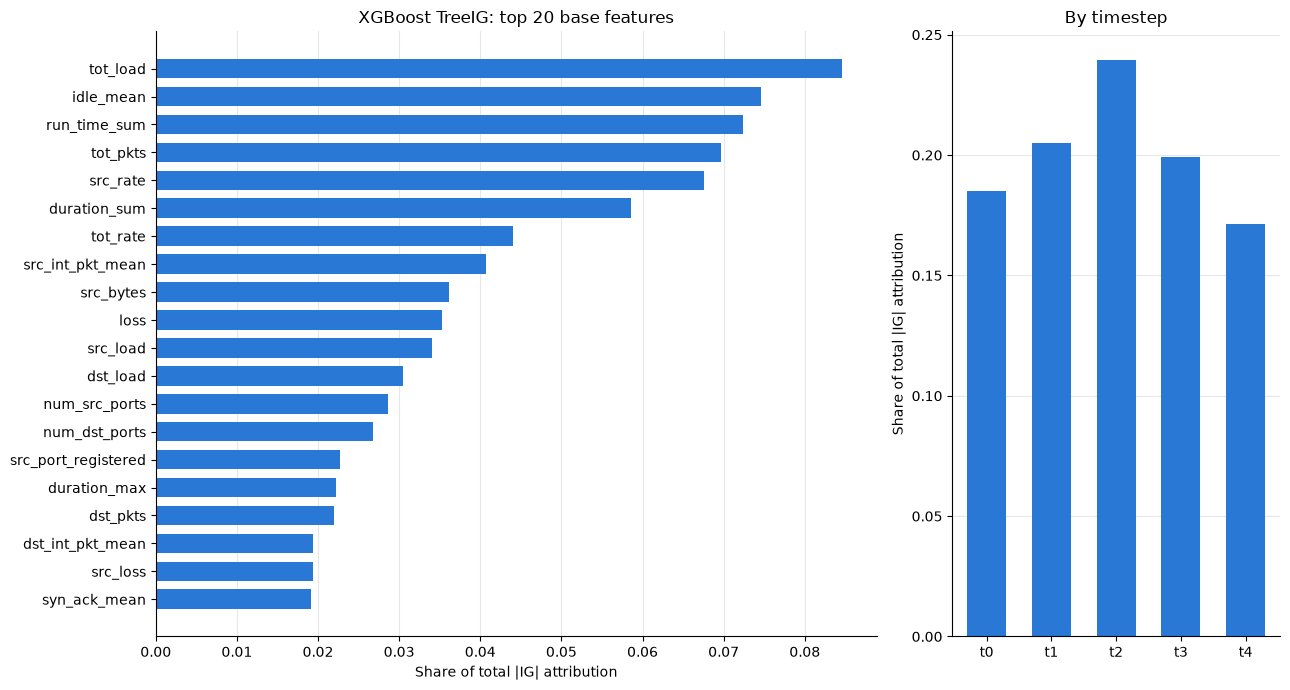

In [25]:
top_ig = feat_df.head(TOP_N)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]
ax.barh(top_ig.feature, top_ig.share, color=CLASS_COLORS['Backdoor'], height=0.7)
ax.set_xlabel('Share of total |IG| attribution')
ax.set_title(f'XGBoost TreeIG: top {TOP_N} base features')

ax = axes[1]
ax.bar(time_df.timestep, time_df.share, color=CLASS_COLORS['Backdoor'], width=0.6)
ax.set_ylabel('Share of total |IG| attribution')
ax.set_title('By timestep')

for ax in axes:
    ax.grid(axis='x' if ax is axes[0] else 'y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Top 10 features for each class (TreeIG)

Mean |IG| over the **correctly predicted** samples of each class, summed over t0-t4. `share` is relative to all 59 features within that class.

In [26]:
correct = pred_ig == y_ig
per_class_results = {}

for c, name in enumerate(CLASSES):
    mask = correct & (y_ig == c)
    if mask.sum() == 0:
        continue
    scores = ig_abs[mask].sum(axis=1).mean(axis=0)
    per_attack = pd.DataFrame({'feature': COLS, 'importance': scores})
    per_attack = per_attack.sort_values('importance', ascending=False).reset_index(drop=True)
    per_attack['share'] = per_attack['importance'] / per_attack['importance'].sum()
    per_attack['rank'] = np.arange(1, len(per_attack) + 1)
    per_class_results[name] = per_attack

    print(f'\n{name}: {mask.sum()} samples')
    display(per_attack.head(10))


Backdoor: 38 samples


,feature,importance,share,rank
0,idle_mean,4.847777,0.348535,1
1,src_loss,1.825205,0.131225,2
2,dst_ttl_mean,0.809501,0.058200,3
3,src_pkts,0.729932,0.052479,4
4,syn_ack_mean,0.697071,0.050117,5
5,src_rate,0.543424,0.039070,6
6,src_load,0.498067,0.035809,7
7,num_src_ports,0.405835,0.029178,8
8,src_bytes,0.336663,0.024205,9
9,src_int_pkt_mean,0.297526,0.021391,10



CommInj: 51 samples


,feature,importance,share,rank
0,idle_mean,1.542882,0.186402,1
1,tot_load,1.185284,0.143199,2
2,src_rate,0.581538,0.070258,3
3,src_load,0.544509,0.065784,4
4,dst_app_bytes,0.498607,0.060239,5
5,tot_rate,0.476254,0.057538,6
6,syn_ack_mean,0.414295,0.050053,7
7,duration_max,0.332550,0.040177,8
8,tcp_rtt_mean,0.322198,0.038926,9
9,dst_load,0.305709,0.036934,10



DoS: 91 samples


,feature,importance,share,rank
0,run_time_sum,2.860589,0.288455,1
1,duration_sum,2.256757,0.227566,2
2,src_port_registered,0.975203,0.098337,3
3,dst_load,0.873892,0.088121,4
4,mean,0.757312,0.076366,5
5,num_src_ports,0.652466,0.065793,6
6,src_int_pkt_mean,0.498238,0.050241,7
7,dst_pkts,0.373875,0.037701,8
8,src_jitter_mean,0.250568,0.025267,9
9,src_ttl_mean,0.153316,0.015460,10



Reconn: 29 samples


,feature,importance,share,rank
0,num_dst_ports,3.514842,0.393766,1
1,dport_registered,1.804187,0.202122,2
2,src_app_bytes,0.562950,0.063067,3
3,dst_rate,0.504988,0.056574,4
4,tot_app_bytes,0.411486,0.046099,5
5,dst_load,0.371853,0.041659,6
6,duration_mean,0.283527,0.031763,7
7,src_ttl_mean,0.208518,0.023360,8
8,proto_6,0.203802,0.022832,9
9,dport_dynamic,0.202341,0.022668,10



normal: 199 samples


,feature,importance,share,rank
0,tot_pkts,1.290967,0.146351,1
1,tot_load,1.278288,0.144914,2
2,src_rate,1.058874,0.120040,3
3,tot_rate,0.730451,0.082808,4
4,loss,0.671537,0.076129,5
5,src_bytes,0.636657,0.072175,6
6,src_int_pkt_mean,0.455123,0.051595,7
7,src_load,0.425814,0.048273,8
8,tot_bytes,0.331808,0.037616,9
9,duration_max,0.307708,0.034884,10


In [27]:
# one table to read across classes: rank 1-10 as rows, one column per class
summary = pd.DataFrame(
    {name: df.feature.head(10).values for name, df in per_class_results.items()},
    index=pd.RangeIndex(1, 11, name='rank'),
)
summary

,Backdoor,CommInj,DoS,Reconn,normal
rank,,,,,
1,idle_mean,idle_mean,run_time_sum,num_dst_ports,tot_pkts
2,src_loss,tot_load,duration_sum,dport_registered,tot_load
3,dst_ttl_mean,src_rate,src_port_registered,src_app_bytes,src_rate
4,src_pkts,src_load,dst_load,dst_rate,tot_rate
5,syn_ack_mean,dst_app_bytes,mean,tot_app_bytes,loss
6,src_rate,tot_rate,num_src_ports,dst_load,src_bytes
7,src_load,syn_ack_mean,src_int_pkt_mean,duration_mean,src_int_pkt_mean
8,num_src_ports,duration_max,dst_pkts,src_ttl_mean,src_load
9,src_bytes,tcp_rtt_mean,src_jitter_mean,proto_6,tot_bytes


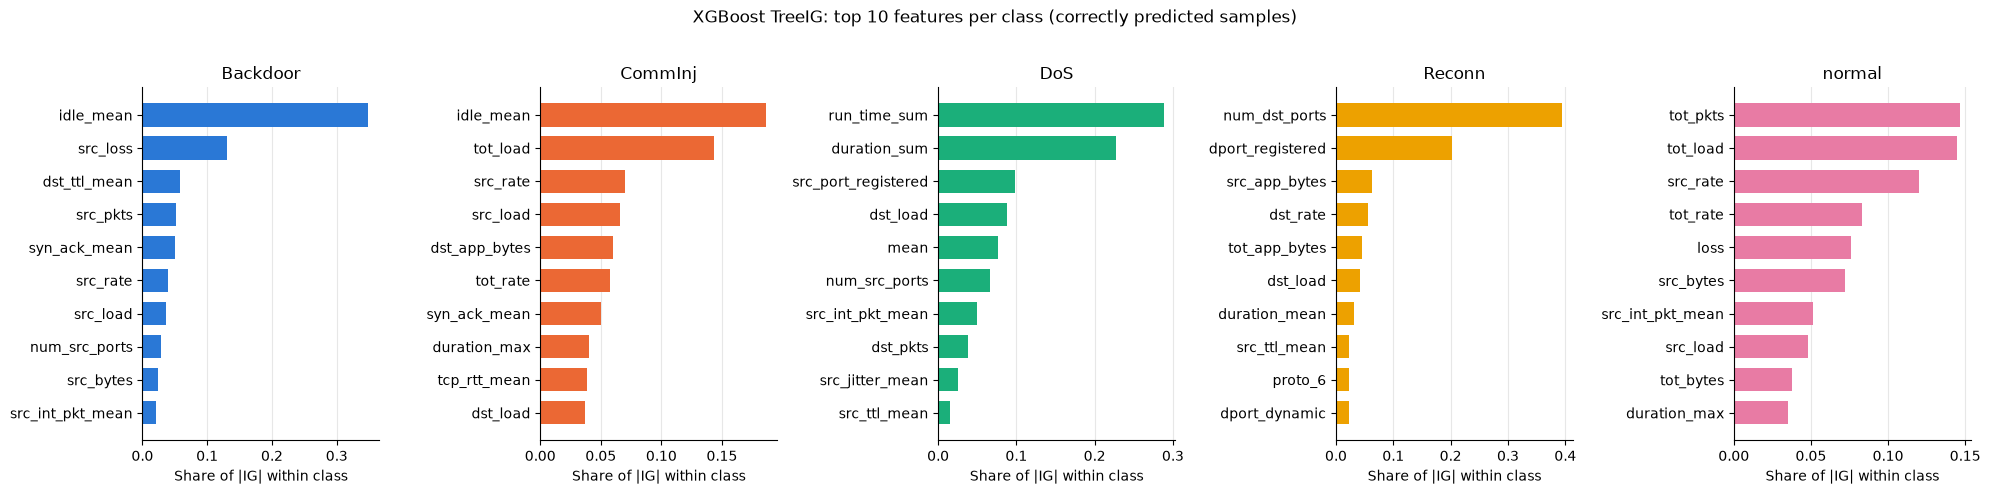

In [28]:
fig, axes = plt.subplots(1, len(per_class_results), figsize=(20, 4.8), sharex=False)
for ax, (name, df) in zip(axes, per_class_results.items()):
    top10_c = df.head(10)[::-1]
    ax.barh(top10_c.feature, top10_c.share, color=CLASS_COLORS[name], height=0.7)
    ax.set_title(name)
    ax.set_xlabel('Share of |IG| within class')
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('XGBoost TreeIG: top 10 features per class (correctly predicted samples)', y=1.02)
plt.tight_layout()
plt.show()

## Comparison with LSTM and GCN (IG)

The LSTM and GCN rankings are copied from the outputs saved in `lstm_explain.ipynb` (`feat_df`, `per_class_results`) and `gcn.ipynb` (`global_importance`, `per_class_results`); those notebooks are not re-run here.

Caveats:
- LSTM and GCN were trained on the **pre-augmentation** data. Augmentation barely changed XGBoost's results, so the comparison is still informative, but the data is not identical.
- GCN importance is the sum of its graph path (IP-node features) and direct path (flow features), as in `gcn.ipynb`.
- Only ranks are compared. A feature outside a model's top 20 (top 10 for the per-class tables) is shown as `>20` (`>10`) and counted as rank 21 (11) for Spearman.

In [29]:
# copied from saved notebook outputs (top 20, in rank order)
LSTM_TOP20 = ['tot_load', 'src_load', 'src_ttl_mean', 'tot_rate', 'dst_ttl_mean', 'src_loss', 'mean',
              'num_dst_ports', 'idle_mean', 'run_time_sum', 'loss', 'src_int_pkt_mean', 'src_jitter_mean',
              'src_rate', 'dport_http', 'src_app_bytes', 'dst_load', 'dst_app_bytes', 'proto_6', 'dst_loss']
GCN_TOP20 = ['num_src_ports', 'src_ttl_mean', 'tot_load', 'dst_ttl_mean', 'num_dst_ports', 'idle_mean',
             'src_loss', 'src_load', 'tot_rate', 'src_rate', 'loss', 'src_jitter_mean', 'run_time_sum', 'mean',
             'dst_loss', 'src_int_pkt_mean', 'dst_pkts', 'stos_0', 'dst_app_bytes', 'dst_bytes']
XGB_TOP20 = feat_df.feature.head(20).tolist()

def rank_table(rankings, top_n):
    features = list(dict.fromkeys(f for r in rankings.values() for f in r))
    ranks = pd.DataFrame({m: [r.index(f) + 1 if f in r else top_n + 1 for f in features]
                          for m, r in rankings.items()}, index=features)
    return ranks.sort_values('XGBoost')

global_ranks = rank_table({'XGBoost': XGB_TOP20, 'LSTM': LSTM_TOP20, 'GCN': GCN_TOP20}, top_n=20)
global_ranks['in_all_top20'] = (global_ranks[['XGBoost', 'LSTM', 'GCN']] <= 20).all(axis=1)

print('Spearman rank correlation over the union of top-20s:')
for a, b in [('XGBoost', 'LSTM'), ('XGBoost', 'GCN'), ('LSTM', 'GCN')]:
    print(f'  {a} vs {b}: {spearmanr(global_ranks[a], global_ranks[b])[0]:.3f}')

global_ranks.replace(21, '>20')

Spearman rank correlation over the union of top-20s:
  XGBoost vs LSTM: 0.129
  XGBoost vs GCN: 0.166
  LSTM vs GCN: 0.713


,XGBoost,LSTM,GCN,in_all_top20
tot_load,1,1,3,True
idle_mean,2,9,6,True
run_time_sum,3,10,13,True
tot_pkts,4,>20,>20,False
src_rate,5,14,10,True
duration_sum,6,>20,>20,False
tot_rate,7,4,9,True
src_int_pkt_mean,8,12,16,True
src_bytes,9,>20,>20,False
loss,10,11,11,True


In [30]:
# per-class top 10s copied from the saved notebook outputs (correctly predicted samples)
LSTM_PER_CLASS = {
    'Backdoor': ['dst_app_bytes', 'dst_ttl_mean', 'dst_bytes', 'dst_loss', 'dst_load',
                 'dst_int_pkt_mean', 'loss', 'dst_pkts', 'idle_mean', 'dport_registered'],
    'CommInj':  ['src_loss', 'loss', 'src_app_bytes', 'dst_loss', 'dst_load',
                 'dst_rate', 'idle_mean', 'dst_ttl_mean', 'dst_pkts', 'dport_modbus'],
    'DoS':      ['tot_load', 'src_load', 'tot_rate', 'mean', 'src_ttl_mean',
                 'run_time_sum', 'src_rate', 'dport_http', 'src_int_pkt_mean', 'src_jitter_mean'],
    'Reconn':   ['num_dst_ports', 'dst_ttl_mean', 'tot_rate', 'proto_6', 'idle_mean',
                 'dport_dynamic', 'src_port_dynamic', 'dport_registered', 'tot_load', 'src_load'],
    'normal':   ['dst_ttl_mean', 'idle_mean', 'src_ttl_mean', 'src_jitter_mean', 'src_app_bytes',
                 'num_src_ports', 'src_int_pkt_mean', 'dst_int_pkt_mean', 'dst_load', 'dst_rate'],
}
GCN_PER_CLASS = {
    'Backdoor': ['dst_app_bytes', 'dst_bytes', 'dst_ttl_mean', 'num_src_ports', 'src_ttl_mean',
                 'dst_loss', 'loss', 'idle_mean', 'src_loss', 'num_dst_ports'],
    'CommInj':  ['src_loss', 'tot_load', 'loss', 'tot_rate', 'src_load',
                 'idle_mean', 'num_src_ports', 'src_rate', 'dst_loss', 'src_ttl_mean'],
    'DoS':      ['run_time_sum', 'src_ttl_mean', 'tot_load', 'mean', 'src_load',
                 'num_src_ports', 'tot_rate', 'src_jitter_mean', 'src_rate', 'src_int_pkt_mean'],
    'Reconn':   ['num_dst_ports', 'idle_mean', 'dst_ttl_mean', 'tot_load', 'src_load',
                 'num_src_ports', 'src_rate', 'tot_rate', 'src_ttl_mean', 'stos_0'],
    'normal':   ['num_src_ports', 'dst_ttl_mean', 'src_ttl_mean', 'src_loss', 'loss',
                 'idle_mean', 'dst_pkts', 'tot_load', 'src_jitter_mean', 'dst_loss'],
}

def bold_shared(table):
    # bold features that appear in all three models' top 10 for this class
    shared = set(table.XGBoost) & set(table.LSTM) & set(table.GCN)
    return table.style.map(lambda v: 'font-weight: bold' if v in shared else '')

for name in CLASSES:
    table = pd.DataFrame({
        'XGBoost': per_class_results[name].feature.head(10).values,
        'LSTM': LSTM_PER_CLASS[name],
        'GCN': GCN_PER_CLASS[name],
    }, index=pd.RangeIndex(1, 11, name='rank'))
    shared = sorted(set(table.XGBoost) & set(table.LSTM) & set(table.GCN))
    print(f'\n{name}: in all three top 10s -> {shared if shared else "none"}')
    display(bold_shared(table))


Backdoor: in all three top 10s -> ['dst_ttl_mean', 'idle_mean']


,XGBoost,LSTM,GCN
rank,,,
1,idle_mean,dst_app_bytes,dst_app_bytes
2,src_loss,dst_ttl_mean,dst_bytes
3,dst_ttl_mean,dst_bytes,dst_ttl_mean
4,src_pkts,dst_loss,num_src_ports
5,syn_ack_mean,dst_load,src_ttl_mean
6,src_rate,dst_int_pkt_mean,dst_loss
7,src_load,loss,loss
8,num_src_ports,dst_pkts,idle_mean
9,src_bytes,idle_mean,src_loss



CommInj: in all three top 10s -> ['idle_mean']


,XGBoost,LSTM,GCN
rank,,,
1,idle_mean,src_loss,src_loss
2,tot_load,loss,tot_load
3,src_rate,src_app_bytes,loss
4,src_load,dst_loss,tot_rate
5,dst_app_bytes,dst_load,src_load
6,tot_rate,dst_rate,idle_mean
7,syn_ack_mean,idle_mean,num_src_ports
8,duration_max,dst_ttl_mean,src_rate
9,tcp_rtt_mean,dst_pkts,dst_loss



DoS: in all three top 10s -> ['mean', 'run_time_sum', 'src_int_pkt_mean', 'src_jitter_mean', 'src_ttl_mean']


,XGBoost,LSTM,GCN
rank,,,
1,run_time_sum,tot_load,run_time_sum
2,duration_sum,src_load,src_ttl_mean
3,src_port_registered,tot_rate,tot_load
4,dst_load,mean,mean
5,mean,src_ttl_mean,src_load
6,num_src_ports,run_time_sum,num_src_ports
7,src_int_pkt_mean,src_rate,tot_rate
8,dst_pkts,dport_http,src_jitter_mean
9,src_jitter_mean,src_int_pkt_mean,src_rate



Reconn: in all three top 10s -> ['num_dst_ports']


,XGBoost,LSTM,GCN
rank,,,
1,num_dst_ports,num_dst_ports,num_dst_ports
2,dport_registered,dst_ttl_mean,idle_mean
3,src_app_bytes,tot_rate,dst_ttl_mean
4,dst_rate,proto_6,tot_load
5,tot_app_bytes,idle_mean,src_load
6,dst_load,dport_dynamic,num_src_ports
7,duration_mean,src_port_dynamic,src_rate
8,src_ttl_mean,dport_registered,tot_rate
9,proto_6,tot_load,src_ttl_mean



normal: in all three top 10s -> none


,XGBoost,LSTM,GCN
rank,,,
1,tot_pkts,dst_ttl_mean,num_src_ports
2,tot_load,idle_mean,dst_ttl_mean
3,src_rate,src_ttl_mean,src_ttl_mean
4,tot_rate,src_jitter_mean,src_loss
5,loss,src_app_bytes,loss
6,src_bytes,num_src_ports,idle_mean
7,src_int_pkt_mean,src_int_pkt_mean,dst_pkts
8,src_load,dst_int_pkt_mean,tot_load
9,tot_bytes,dst_load,src_jitter_mean


## TreeIG vs baseline SHAP for XGBoost

Both methods now use the same model, samples, all-zeros baseline and predicted-class target, and both add up to `f(x) - f(0)`. The only difference is how credit is shared between interacting features: baseline SHAP averages over every order of switching features from 0 to their value, while IG moves all features together along one straight line. Where the two rankings agree, the result does not depend on the choice of attribution method.

In [31]:
shap_overall = shap_feat_df.set_index('feature')['importance'].reindex(COLS)
ig_overall = feat_df.set_index('feature')['feature_importance'].reindex(COLS)
rows = [{'scope': 'global',
         'spearman_all_59': spearmanr(ig_overall, shap_overall)[0],
         'top10_overlap': len(set(ig_overall.nlargest(10).index) & set(shap_overall.nlargest(10).index)),
         'same_top1': ig_overall.idxmax() == shap_overall.idxmax()}]
for name in CLASSES:
    a = per_class_results[name].set_index('feature')['importance'].reindex(COLS)
    b = shap_per_class[name].set_index('feature')['importance'].reindex(COLS)
    rows.append({'scope': name, 'spearman_all_59': spearmanr(a, b)[0],
                 'top10_overlap': len(set(a.nlargest(10).index) & set(b.nlargest(10).index)),
                 'same_top1': a.idxmax() == b.idxmax()})
pd.DataFrame(rows).set_index('scope').round(3)

,spearman_all_59,top10_overlap,same_top1
scope,,,
global,0.951,8,False
Backdoor,0.944,7,True
CommInj,0.946,8,False
DoS,0.919,9,True
Reconn,0.936,8,True
normal,0.849,7,False


Note: `idle_mean` is the timestamp leak described in Part 1 (section 8). It shows up in the IG rankings of all three models.

In [32]:
ig_out = feat_df.set_index('feature')[['feature_importance', 'share', 'rank']]
for name, df in per_class_results.items():
    ig_out[f'importance_{name}'] = df.set_index('feature')['importance']
ig_out.to_csv(f'{MODEL_DIR}/xgboost_ig_importance.csv')
ig_out.head()

,feature_importance,share,rank,importance_Backdoor,importance_CommInj,importance_DoS,importance_Reconn,importance_normal
feature,,,,,,,,
tot_load,0.801258,0.084632,1,0.248945,1.185284,0.000000,0.068418,1.278288
idle_mean,0.705768,0.074546,2,4.847777,1.542882,0.000000,0.019230,0.114898
run_time_sum,0.685284,0.072382,3,0.132661,0.178556,2.860589,0.007416,0.038259
tot_pkts,0.659134,0.069620,4,0.266842,0.000063,0.000000,0.039924,1.290967
src_rate,0.639557,0.067552,5,0.543424,0.581538,0.000000,0.000000,1.058874
